# Predicting Eco-Friendly Menstrual Product Switching Intent

**Goal:** Using a self-collected survey of 333 respondents on menstrual hygiene product usage, predict whether a respondent is likely to switch to an eco-friendly menstrual product. This kind of model could help NGOs, health-tech startups, or sustainable-product brands identify which demographic/behavioral segments to target with awareness campaigns.

**Dataset:** `menstrual_hygiene_survey.csv` — 333 respondents, 24 survey questions covering demographics, current product usage, disposal habits, awareness of menstrual waste, and attitudes toward eco-friendly alternatives.

**Target variable:** `Switching to eco friendly menstrual product` (Yes / Maybe / No), collapsed into a binary target:
- `1` = Yes (intends to switch)
- `0` = Maybe or No (not currently intending to switch)

**Approach:**
1. Data cleaning and structuring
2. Exploratory Data Analysis (EDA)
3. Feature engineering
4. Preprocessing pipeline (`ColumnTransformer` + `Pipeline`)
5. Model training with 5-fold Stratified Cross-Validation (Logistic Regression, Random Forest, XGBoost)
6. Model explainability with SHAP
7. Saving the final pipeline for deployment


## 1. Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, RocCurveDisplay
from xgboost import XGBClassifier
import shap
import joblib

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
RANDOM_STATE = 42

## 2. Load Data

The file uses `latin1` encoding (contains special characters from survey text responses).

In [ ]:
df = pd.read_csv('menstrual.csv', encoding='latin1')
print('Shape:', df.shape)
df.head()

In [ ]:
df.info()

## 3. Data Cleaning

Steps:
- Drop the stray `Unnamed: 23` column
- Strip whitespace from all text fields (survey exports often have trailing spaces, e.g. `'Sanitary napkins '` vs `'Sanitary napkins'`)
- Convert `Income` to numeric (values like `10,000` have commas)
- Extract a clean numeric `years_using_product` from the messy `No.of years using menstrual product` column (some entries are free text like `'From 1st period (from age 15yr )'` or `'20yrs'`)
- Convert `No.of products used for a cycle` to numeric (`'More than 20'` -> `25`)


In [ ]:
#df = df.drop(columns=['Unnamed: 23'])

# Strip whitespace / normalize text columns
for c in df.select_dtypes(include='object').columns:
    df[c] = df[c].astype(str).str.strip().replace('nan', np.nan)

# Income: remove commas, convert to numeric, impute missing with median
df['Income'] = pd.to_numeric(df['Income'].str.replace(',', '', regex=False), errors='coerce')
df['Income'] = df['Income'].fillna(df['Income'].median())

# Years using product: extract the numeric part, impute missing with median
years_extracted = df['No.of years using menstrual product'].str.extract(r'(\d+)').astype(float)
df['years_using_product'] = years_extracted[0].fillna(years_extracted[0].median())
df = df.drop(columns=['No.of years using menstrual product'])

# Products per cycle: convert 'More than 20' to a numeric approximation
df['No.of products used for a cycle'] = (
    df['No.of products used for a cycle'].replace('More than 20', '25').astype(float)
)

print('Missing values after cleaning:')
print(df.isnull().sum()[df.isnull().sum() > 0])

## 4. Define the Target Variable

`Switching to eco friendly menstrual product` has 3 classes: `Yes` (226), `Maybe` (85), `No` (22).

`Maybe` and `No` are collapsed into `0` (not currently intending to switch), since `No` alone is too small a class (22 rows) to model reliably on its own, and both groups represent respondents who are *not* committed switchers.


In [ ]:
print(df['Switching to eco friendly menstrual product'].value_counts())

df['switch_intent'] = df['Switching to eco friendly menstrual product'].map(
    {'Yes': 1, 'Maybe': 0, 'No': 0}
)

print()
print(df['switch_intent'].value_counts())
print(f"Positive class rate: {df['switch_intent'].mean():.1%}")

## 5. Exploratory Data Analysis

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df['Age'], bins=15, kde=True, ax=axes[0], color='teal')
axes[0].set_title('Age Distribution')

sns.countplot(x='switch_intent', data=df, ax=axes[1], palette=['#d9d9d9', '#008080'])
axes[1].set_title('Target Class Balance (0 = Maybe/No, 1 = Yes)')

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, ['Area', 'Occupation', 'Awareness about impact of menstrual waste ']):
    rate = df.groupby(col)['switch_intent'].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color='teal')
    ax.set_ylabel('Switch intent rate')
    ax.set_title(f'Switch intent by {col.strip()}')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
rate = df.groupby('Manufacturer should produce eco friendly products')['switch_intent'].mean()
order = ['Disagree', 'Neutral', 'Agree', 'Strongly agree']
rate = rate.reindex(order)
sns.barplot(x=rate.index, y=rate.values, color='teal', ax=ax)
ax.set_ylabel('Switch intent rate')
ax.set_title('Switch intent by attitude toward manufacturers going eco-friendly')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Observations to note in your presentation:**
- Compare switch-intent rate across urban vs rural respondents and across occupations.
- Awareness of menstrual waste impact is a hypothesized driver of switching intent — check whether the EDA supports this.
- Stronger agreement that manufacturers should produce eco-friendly products tends to track with higher switch intent, which is a good sanity check that the target is behaving sensibly.


## 6. Feature Engineering

- `reason_given`: binary flag for whether the respondent filled in the free-text `Reasons` field (263/333 left this blank — the *fact* they answered may itself be informative, even though we can't use the free text directly without NLP)
- `product_reason_given`: same idea for `Reason for particular product`
- Drop the original free-text columns (`Reasons`, `Reason for particular product`) and the now-redundant source target column


In [ ]:
df['reason_given'] = df['Reasons'].notna().astype(int)
df['product_reason_given'] = df['Reason for particular product'].notna().astype(int)

df_model = df.drop(columns=[
    'Switching to eco friendly menstrual product',
    'Reasons',
    'Reason for particular product'
])

y = df_model['switch_intent']
X = df_model.drop(columns=['switch_intent'])

print(X.shape, y.shape)

## 7. Preprocessing Pipeline

Columns are grouped into three types, each handled by its own sub-pipeline inside a `ColumnTransformer`:

- **Numeric** (`Age`, `Income`, products per cycle, years using product) — median impute + scale
- **Ordinal** (columns with a natural order, e.g. flow intensity, cost brackets) — most-frequent impute + `OrdinalEncoder` with an explicit category order
- **Nominal** (unordered categories, e.g. Occupation, Area) — most-frequent impute + one-hot encode
- **Binary passthrough** (already 0/1 engineered flags)

This mirrors the same `Pipeline` + `ColumnTransformer` pattern used in the telecom churn project, for consistency across projects.


In [ ]:
numeric_features = ['Age', 'Income', 'No.of products used for a cycle', 'years_using_product']

ordinal_features = {
    'Intensity of flow': ['Low', 'Medium', 'High'],
    'Single day changing frequency': ['Less than 3 times', '3-5 times', 'More than 5 times'],
    'Duration of single product per day': ['1-3 hours', '4-6 hours', 'More than 6 hours'],
    'Monthly cost spend': ['Less than 100 Rs', '100-150 Rs', '150-200 Rs', 'More than 200 Rs'],
    'Manufacturer should produce eco friendly products': ['Disagree', 'Neutral', 'Agree', 'Strongly agree'],
}

binary_passthrough = ['reason_given', 'product_reason_given']

nominal_features = [
    c for c in X.columns
    if c not in numeric_features and c not in ordinal_features and c not in binary_passthrough
]

print('Numeric:', numeric_features)
print('Ordinal:', list(ordinal_features.keys()))
print('Nominal:', nominal_features)
print('Binary passthrough:', binary_passthrough)

In [ ]:
numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

ordinal_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OrdinalEncoder(categories=[ordinal_features[c] for c in ordinal_features]))
])

nominal_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('ord', ordinal_pipe, list(ordinal_features.keys())),
    ('nom', nominal_pipe, nominal_features),
    ('bin', 'passthrough', binary_passthrough),
])

## 8. Model Training & Cross-Validation

With only 333 rows, a single train/test split would give noisy, unreliable metrics. Instead we use **5-fold Stratified Cross-Validation**, which preserves the class ratio in every fold and averages performance across all 5 splits.

Three models are compared, all using class weighting to handle the ~68/32 class imbalance:
- Logistic Regression (interpretable baseline)
- Random Forest
- XGBoost


In [ ]:
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=300, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(
        scale_pos_weight=(y == 0).sum() / (y == 1).sum(),
        eval_metric='logloss',
        random_state=RANDOM_STATE
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['roc_auc', 'f1', 'precision', 'recall', 'accuracy']

cv_results = {}
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', model)])
    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    cv_results[name] = {s: scores['test_' + s].mean() for s in scoring}

results_df = pd.DataFrame(cv_results).T
results_df.round(3)

In [ ]:
results_df[['roc_auc', 'f1', 'precision', 'recall']].plot(
    kind='bar', figsize=(9, 5), color=['#008080', '#40b0b0', '#80c0c0', '#b3dede']
)
plt.title('5-Fold Cross-Validated Performance by Model')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Reading these numbers honestly:** with 333 respondents and a survey-based target, ROC-AUC in the 0.58–0.65 range is realistic and expected — not a sign of a bug. Be ready to explain this in an interview: the value of this project is the *engineering process and the explainability insights*, not a claim of a highly predictive model. Reporting an inflated AUC on this sample size would be a red flag to an experienced interviewer.


## 9. Confusion Matrix & Classification Report (Best Model)

Using cross-validated predictions (`cross_val_predict`) so the evaluation is still out-of-fold, not just refit-and-check.


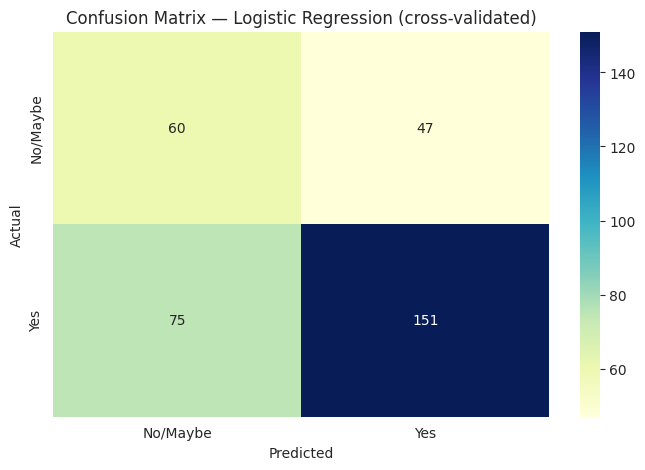

In [ ]:
best_model_name = results_df['roc_auc'].idxmax()
print('Best model by ROC-AUC:', best_model_name)

best_pipe = Pipeline([('prep', preprocessor), ('clf', models[best_model_name])])
y_pred = cross_val_predict(best_pipe, X, y, cv=cv, method='predict')

print(classification_report(y, y_pred, target_names=['No/Maybe (0)', 'Yes (1)']))

cm = confusion_matrix(y, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=['No/Maybe', 'Yes'], yticklabels=['No/Maybe', 'Yes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix — {best_model_name} (cross-validated)')
plt.show()

## 10. Fit Final Pipeline on Full Data

For the deployed/saved model, fit the best pipeline on the entire dataset (cross-validation above was only for honest performance estimation).


In [ ]:
final_pipe = Pipeline([('prep', preprocessor), ('clf', models[best_model_name])])
final_pipe.fit(X, y)
print('Final pipeline fitted on full dataset.')

## 11. Explainability with SHAP

This is the part that makes the project resume-worthy beyond a bare accuracy number: SHAP shows *which factors drive predicted switching intent*, which is exactly the kind of insight a sustainability brand or NGO would act on.


In [ ]:
# Transform features through the preprocessor to get the final feature matrix
X_transformed = final_pipe.named_steps['prep'].transform(X)
feature_names = final_pipe.named_steps['prep'].get_feature_names_out()

X_transformed_df = pd.DataFrame(
    X_transformed.toarray() if hasattr(X_transformed, 'toarray') else X_transformed,
    columns=feature_names
)

clf = final_pipe.named_steps['clf']

if best_model_name == 'Logistic Regression':
    explainer = shap.LinearExplainer(clf, X_transformed_df)
else:
    explainer = shap.TreeExplainer(clf)

shap_values = explainer.shap_values(X_transformed_df)

# For binary classifiers that return a list of arrays, take the positive class
if isinstance(shap_values, list):
    shap_values = shap_values[1]

In [ ]:
shap.summary_plot(shap_values, X_transformed_df, show=False, max_display=15)
plt.title(f'SHAP Feature Importance — {best_model_name}')
plt.tight_layout()
plt.show()

**In your presentation/interview, translate the top SHAP features into plain language**, e.g. *"Awareness of menstrual waste impact and positive attitudes toward eco-friendly manufacturing were the strongest predictors of switching intent, more so than income or area."* Fill in with whatever your actual SHAP output shows.


## 12. Save the Final Pipeline

Saved with `joblib`, same as the telecom churn project, so it can be loaded directly into a Streamlit app for deployment.


In [ ]:
joblib.dump(final_pipe, 'eco_switch_intent_pipeline.joblib')
print('Saved: eco_switch_intent_pipeline.joblib')

## 13. Summary & Next Steps

**What this project demonstrates:**
- End-to-end ML workflow on real, self-collected survey data (data cleaning is genuinely messy here — free text fields, inconsistent units, commas in numbers)
- Thoughtful problem framing (justified binarization of a 3-class target)
- Proper handling of a small dataset (Stratified K-Fold instead of a single train/test split)
- Class imbalance handling via `class_weight='balanced'` / `scale_pos_weight`
- Honest performance reporting instead of overfitting to a tiny sample
- Model explainability via SHAP, tied back to actionable business/social insight

**Possible extensions (stretch goals):**
- Try the original 3-class target (Yes / Maybe / No) as a multiclass problem
- Simple NLP (keyword extraction or topic modeling) on the free-text `Reasons` column
- Deploy as a Streamlit app where a user inputs demographics and gets a predicted switch-likelihood plus top SHAP drivers
- Collect more responses to shrink the confidence intervals on these metrics
